# Customer Churn Prediction

### Crack404 AI/ML Internship – Week 1

This notebook develops a baseline machine-learning solution for customer churn prediction using the Telco Customer Churn dataset. The workflow includes data inspection, cleaning, categorical encoding, train-test splitting, Random Forest classification, Recall-focused evaluation, threshold adjustment, and feature-importance analysis. Because the business objective is to identify as many customers at risk of churn as possible, particular attention is given to Recall for the churn class.

## 1. Importing Libraries

The required libraries are imported for data manipulation, numerical operations, visualization, preprocessing, model training, and model evaluation.

In [3]:
import pandas as pd
import numpy as np

print("Pandas is ready!")
print("NumPy is ready!")

Pandas is ready!
NumPy is ready!


## 2. Loading the Dataset

The Telco Customer Churn dataset is loaded into a Pandas DataFrame. Each row represents one customer, while the columns describe customer characteristics, subscribed services, account information, charges, and churn status.

In [4]:
# from google.colab import files

# uploaded = files.upload()


In [5]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


## 3. Initial Data Inspection

The dataset is inspected using its first rows, shape, column names, data types, summary statistics, and general structure. This step helps identify potential data-quality problems before preprocessing.

In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.shape

(7043, 21)

In [8]:
df.columns.to_list()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']


In [12]:
categorical_columns = df.select_dtypes(include=["object", "string", "category"]).columns

print("Categorical Columns: ")
print(categorical_columns.to_list())

Categorical Columns: 
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [13]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [14]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## 4. Data Cleaning

The dataset is checked for missing, blank, and incorrectly typed values. `TotalCharges` requires particular attention because it represents a numerical quantity but is initially stored as an object data type.

In [15]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df["TotalCharges"].dtype

dtype('O')

In [17]:
blank_count = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Blank TotalCharges values:", blank_count)

Blank TotalCharges values: 11


### Cleaning `TotalCharges`

`TotalCharges` is converted to a numerical data type. Invalid blank entries are converted to missing values (`NaN`). Only 11 records are affected, which represents a very small proportion of the dataset, so these records are removed rather than imputed. This avoids introducing estimated values while having minimal effect on the overall dataset.

In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [19]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [20]:
missing_customers = df[
    df["TotalCharges"].isnull()
]

missing_customers[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [21]:
# Keep the original DataFrame unchanged
df_clean = df.dropna(
    subset=["TotalCharges"]
).copy()

print("Before cleaning:", df.shape)
print("After cleaning:", df_clean.shape)

Before cleaning: (7043, 21)
After cleaning: (7032, 21)


In [22]:
print(df_clean.isnull().sum())
print(df_clean["TotalCharges"].dtype)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
float64


In [23]:
print(df_clean.shape)

(7032, 21)


In [24]:
print(df_clean.duplicated().sum())

0


## 5. Exploratory Data Analysis

The cleaned dataset is explored to understand the distribution of the target variable and the structure of the available features. The churn distribution is particularly important because an imbalanced target can make Accuracy alone misleading.

In [25]:
print(df_clean["Churn"].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [26]:
print(df_clean["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

Matplotlib is building the font cache; this may take a moment.


ModuleNotFoundError: No module named 'seaborn'

In [ ]:
categorical_columns = df_clean.select_dtypes(include="object").columns

print(categorical_columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')


In [ ]:
numerical_columns = df_clean.select_dtypes(include=["int64", "float64"]).columns

print(numerical_columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


## 6. Preparing the Dataset for Machine Learning

The `customerID` column is removed because it is a unique identifier rather than a meaningful behavioural or account feature. Including it would not provide useful information for predicting churn.

The `Churn` target is converted from `No` and `Yes` into numerical values `0` and `1`, where `1` represents a customer who churned.

In [ ]:
df_model = df_clean.drop("customerID", axis=1).copy()

In [ ]:
df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(df_model.shape)

(7032, 20)


In [ ]:
df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [ ]:
print(df_model["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [ ]:
print(df_model["Churn"].dtype)

int64


### Separating Features and Target

The predictor variables are stored in `X`, while the churn outcome is stored in `y`. This separates the information available to the model from the outcome that the model is expected to predict.

In [ ]:
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7032, 19)
y shape: (7032,)


In [ ]:
categorical_features = X.select_dtypes(include="object").columns.tolist()

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

In [ ]:
print("Categorical features:")
print(categorical_features)

print()

print("Numerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 7. Categorical Data Encoding

Categorical features are transformed into numerical values using One-Hot Encoding because machine-learning models require numerical input. `handle_unknown="ignore"` allows the preprocessing pipeline to safely handle categories that may not have appeared during training.

Feature scaling is not applied because Random Forest is a tree-based model. Tree splits depend on feature thresholds rather than distances or feature magnitudes, so scaling is not required for this model.

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

## 8. Train-Test Split

The dataset is divided into 80% training data and 20% testing data. Stratification is used so that the proportion of churn and non-churn customers remains approximately consistent in both sets.

A fixed `random_state=42` is used to make the experiment reproducible. The number 42 has no special statistical meaning; any fixed integer could be used for reproducibility.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 19)
X_test shape: (1407, 19)
y_train shape: (5625,)
y_test shape: (1407,)


In [ ]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


## 9. Baseline Random Forest Model

A pipeline combines the preprocessing stage with a Random Forest Classifier. The Random Forest is initially trained using its standard baseline configuration, with a fixed random state for reproducibility.

This model is treated as a baseline rather than a fully hyperparameter-optimized Random Forest.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42
            )
        )
    ]
)

# model_balanced = Pipeline(
#     steps=[
#         ("preprocessor", preprocessor),
#         (
#             "classifier",
#             RandomForestClassifier(
#                 random_state=42,
#                 class_weight="balanced"
#             )
#         )
#     ]
# )

### Additional Experiment: Class Weight Adjustment

A class-weighted Random Forest was tested as an alternative method for addressing class imbalance. However, it produced lower churn Recall than the baseline model, so it was not selected for the final approach.

In [ ]:
model.fit(X_train, y_train)

# model_balanced.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
y_pred = model.predict(X_test)

# y_pred_balanced = model_balanced.predict(X_test)

## 10. Baseline Model Evaluation

The baseline model is evaluated using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix. Recall for the churn class is especially important because a False Negative represents a customer who actually churns but is incorrectly predicted to remain.

The baseline model achieved approximately **79.2% Accuracy** and approximately **51% Recall for churn**, meaning that almost half of the actual churn customers were still being missed.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score

In [ ]:
print(classification_report(y_test, y_pred))

# print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Churn Recall:", recall)

# balanced_accuracy = accuracy_score(y_test, y_pred_balanced)
# balanced_recall = recall_score(y_test, y_pred_balanced)

# print("Accuracy:", balanced_accuracy)
# print("Churn Recall:", balanced_recall)

Accuracy: 0.7924662402274343
Churn Recall: 0.5080213903743316


In [ ]:
cm = confusion_matrix(y_test, y_pred)
# cm = confusion_matrix(y_test, y_pred_balanced)
print(cm)

[[925 108]
 [184 190]]


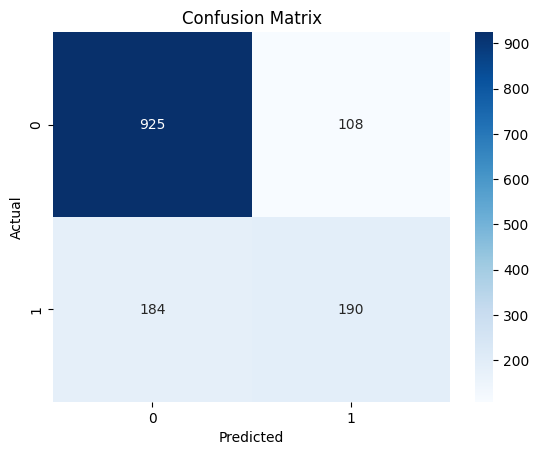

In [ ]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

print("Accuracy:", accuracy)
print("Churn Recall:", recall)

# print(classification_report(y_test, y_pred_balanced))

# print("Accuracy:", balanced_accuracy)
# print("Churn Recall:", balanced_recall)

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

Accuracy: 0.7924662402274343
Churn Recall: 0.5080213903743316


## 11. Recall Optimization Through Threshold Adjustment

The default classification threshold is 0.50. Because the business objective prioritizes identifying as many actual churn customers as possible, lower probability thresholds are tested.

Reducing the threshold causes more customers to be classified as potential churners. This generally increases Recall but can also increase False Positives and reduce overall Accuracy and Precision.

In [ ]:
y_proba = model.predict_proba(X_test)[:, 1]

### Threshold Comparison

Several probability thresholds are compared to examine the trade-off between churn Recall and overall Accuracy.

In [ ]:
for threshold in [0.50, 0.45, 0.40, 0.35, 0.30]:
    y_pred_temp = (y_proba >= threshold).astype(int)

    recall_temp = recall_score(y_test, y_pred_temp)
    accuracy_temp = accuracy_score(y_test, y_pred_temp)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Recall: {recall_temp:.3f} | "
        f"Accuracy: {accuracy_temp:.3f}"
    )

Threshold: 0.50 | Recall: 0.513 | Accuracy: 0.791
Threshold: 0.45 | Recall: 0.570 | Accuracy: 0.783
Threshold: 0.40 | Recall: 0.612 | Accuracy: 0.765
Threshold: 0.35 | Recall: 0.690 | Accuracy: 0.751
Threshold: 0.30 | Recall: 0.749 | Accuracy: 0.741


### Final Threshold Selection

A final threshold of **0.40** is selected as a practical trade-off between Recall and overall predictive performance. Compared with the default threshold of 0.50, it increases churn Recall from approximately **51% to 61%**, while maintaining overall Accuracy at approximately **76.5%**.

Although thresholds such as 0.35 and 0.30 produce even higher Recall, they also classify substantially more non-churning customers as churners and reduce overall Accuracy further. Therefore, 0.40 is selected as a balanced Recall-focused threshold rather than simply choosing the threshold with the highest possible Recall.

In [ ]:
final_threshold = 0.40

y_pred_final = (y_proba >= final_threshold).astype(int)

## 12. Final Model Evaluation

The final predictions are generated using the selected probability threshold of 0.40. The resulting classification report and Confusion Matrix are used to evaluate the Recall-focused model.

The final model achieves approximately **76.5% Accuracy** and **61.2% churn Recall**. The reduction in Accuracy is accepted because the objective of this task is to identify more customers who are genuinely at risk of churn.

In [ ]:
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           0       0.85      0.82      0.84      1033
           1       0.55      0.61      0.58       374

    accuracy                           0.77      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.77      0.77      0.77      1407



In [ ]:
final_accuracy = accuracy_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)

print("Final Accuracy:", final_accuracy)
print("Final Churn Recall:", final_recall)

Final Accuracy: 0.7654584221748401
Final Churn Recall: 0.6122994652406417


In [ ]:
cm_final = confusion_matrix(y_test, y_pred_final)

print(cm_final)

[[848 185]
 [145 229]]


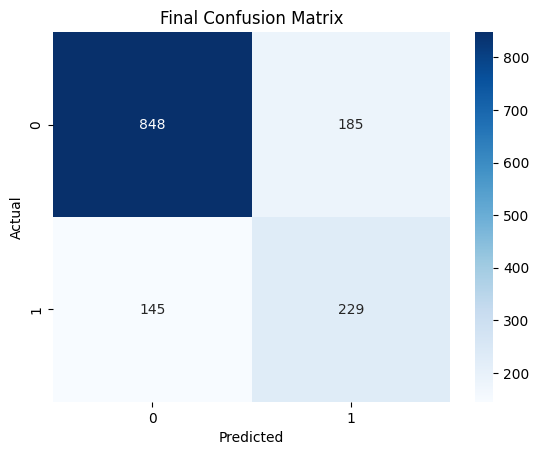

In [ ]:
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Confusion Matrix")
plt.show()

### Overfitting Check

Training and testing performance are compared to examine model generalization. The Random Forest achieves almost perfect performance on the training data but noticeably lower performance on the testing data.

This gap suggests that the baseline Random Forest is overfitting to some extent. Hyperparameters such as `max_depth`, `min_samples_split`, `min_samples_leaf`, and the number of trees could be tuned in future work to improve generalization.

In [ ]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.9987555555555555
Testing Accuracy: 0.7924662402274343


## 13. Feature Importance

Random Forest feature-importance scores are examined to identify which variables contributed most strongly to the model's churn predictions.

These scores indicate predictive importance within this model and should not be interpreted as evidence that the variables directly cause customer churn.

In [ ]:
encoded_features = (
    model.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .get_feature_names_out(categorical_features)
)

In [ ]:
all_features = list(encoded_features) + numerical_features

In [ ]:
importances = model.named_steps["classifier"].feature_importances_

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": all_features,
    "Importance": importances
})

In [ ]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [ ]:
feature_importance.head(10)

,Feature,Importance
44,TotalCharges,0.159947
42,tenure,0.143731
43,MonthlyCharges,0.136979
32,Contract_Month-to-month,0.045162
14,OnlineSecurity_No,0.035615
39,PaymentMethod_Electronic check,0.030455
23,TechSupport_No,0.029192
12,InternetService_Fiber optic,0.023798
41,SeniorCitizen,0.020525
34,Contract_Two year,0.020389


### Top 10 Predictors of Customer Churn

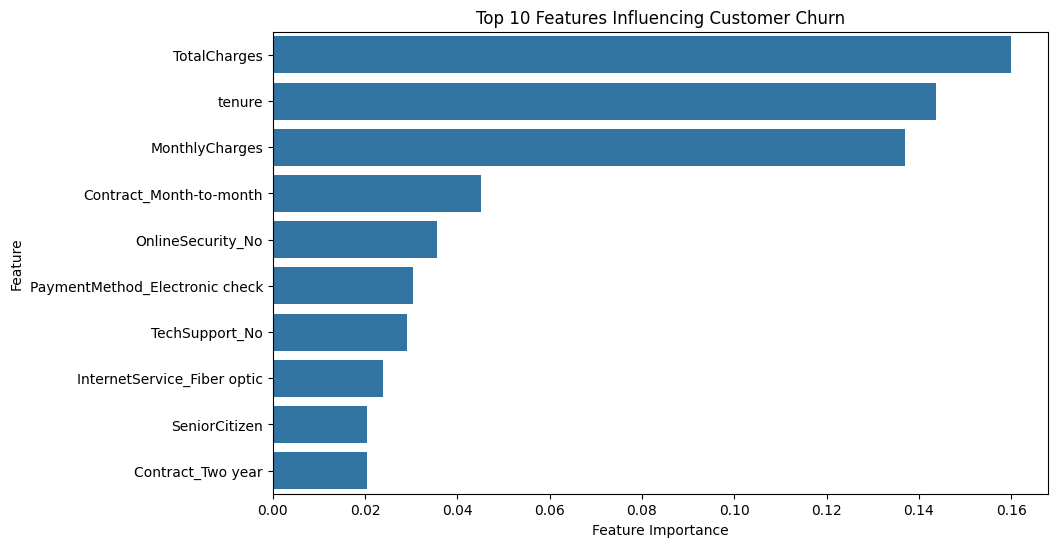

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

## 14. Conclusion and Strongest Predictors

The Random Forest feature-importance analysis identified **TotalCharges, tenure, and MonthlyCharges** as the strongest predictors of customer churn. Contract type was also influential, particularly **month-to-month contracts**, while the absence of **Online Security** and **Tech Support** contributed strongly to the model's predictions. Other important features included **Electronic Check payment**, **Fiber Optic Internet Service**, **Senior Citizen status**, and **Two-Year Contract status**. Overall, the findings indicate that customer spending, length of the customer relationship, contract commitment, payment method, internet service type, and access to support-related services are important predictive factors in identifying customers at risk of churn.

### Limitations and Future Improvement

The baseline Random Forest shows evidence of overfitting because its training performance is substantially higher than its testing performance. Future work could therefore include Random Forest hyperparameter tuning and cross-validation. In addition, the probability threshold in this notebook was compared using the available test data. A stronger evaluation design would use a separate validation set for threshold selection and reserve an untouched test set solely for the final performance evaluation. More advanced feature-interpretation methods, such as permutation importance or SHAP, could also be considered in future analysis.